# 02 · Price analysis: what is a fair price on Tiki?

**Business question:** a shopper (or a seller setting a price) wants to know, for one type of product, *what price is normal*, *below which price a listing looks suspicious*, and *which price range actually sells*.

**Data:** `data/sample/tiki_sample.csv`, built in `01_data_collection.ipynb` — products listed on Tiki for three keywords from different product types, collected at the same moment.

**Questions**

1. Is the data good enough to analyse?
2. What does the price distribution look like, and which prices are unusual?
3. What are the reference prices (floor, common range, median)?
4. Which price segment sells — and how concentrated are sales?
5. What is related to sales: price, rating, discount, reviews?
6. What does the deal score pick, and is it validated?

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, PercentFormatter

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from analysis.pricing import add_analysis_columns, price_band, price_fences, weighted_median

FIGURES = ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

# Chart style: one colour per keyword, a light grid, no top/right border
BLUE, ORANGE, GREEN, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#b0b0b0"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
# 250000 -> "250K", 1500000 -> "1.5M"
vnd_short = FuncFormatter(lambda x, _: f"{x / 1e6:g}M" if x >= 1e6 else f"{x / 1e3:g}K")
pd.set_option("display.max_colwidth", 55)

## 1. Is the data good enough to analyse?

In [2]:
df = pd.read_csv(ROOT / "data" / "sample" / "tiki_sample.csv")

# Recompute the price flags and deal scores with today's analysis/pricing.py: the values saved
# in the CSV come from the code at collection time. Each keyword is analysed on its own.
frames = []
for keyword, group in df.groupby("keyword", sort=False):
    frames.append(add_analysis_columns(group))
df = pd.concat(frames, ignore_index=True)

KEYWORDS = list(df["keyword"].unique())
COLORS = dict(zip(KEYWORDS, [BLUE, ORANGE, GREEN]))

print(df.shape)
print("Collected at:", df["crawled_at"].iloc[0])
df.groupby("keyword").agg(products=("product_id", "size"), categories=("category", "nunique"))

(567, 18)
Collected at: 2026-10-24 10:27


,products,categories
keyword,,
chuột gaming,173,5
nồi chiên không dầu,197,4
tai nghe bluetooth,197,19


In [3]:
# Data quality checks: every line should print True
checks = {
    "no duplicated product per keyword": not df.duplicated(["keyword", "source", "product_id"]).any(),
    "every price > 0":                   (df["price"] > 0).all(),
    "original price >= price":           (df["original_price"] >= df["price"]).all(),
    "discount between 0 and 100 %":      df["discount_pct"].between(0, 100).all(),
    "rating empty or between 1 and 5":   df["rating"].dropna().between(1, 5).all(),
    "sold and reviews never negative":   (df[["sold", "review_count"]] >= 0).all().all(),
    "every product has a link":          df["product_url"].notna().all(),
}
for name, ok in checks.items():
    print(f"{ok!s:>5}  {name}")

 True  no duplicated product per keyword
 True  every price > 0
 True  original price >= price
 True  discount between 0 and 100 %
 True  rating empty or between 1 and 5
 True  sold and reviews never negative
 True  every product has a link


In [4]:
# Missing values: only brand and rating may be empty, and both are expected
missing = (df.isna().mean() * 100).round(1)
missing[missing > 0].to_frame("missing %")

,missing %
brand,3.0
rating,69.0
deal_score,3.4


Brand is empty for "OEM / No Brand" products, and rating is empty for products **nobody has rated yet** — after cleaning, empty does not mean zero.

### Analyse one category at a time

A search for "chuột gaming" also returns mouse pads; "tai nghe bluetooth" returns several kinds of headphones. Mixing them would distort every price statistic, so each keyword is analysed on its **main category** (the most common one).

In [5]:
rows = []
for keyword, group in df.groupby("keyword", sort=False):
    counts = group["category"].value_counts()  # biggest category first
    rows.append({"keyword": keyword, "main category": counts.index[0],
                 "share of results %": round(100 * counts.iloc[0] / len(group), 1)})
main_categories = pd.DataFrame(rows).set_index("keyword")
main_categories

,main category,share of results %
keyword,,
chuột gaming,Chuột Chơi Game,87.9
tai nghe bluetooth,Tai Nghe True Wireless,36.0
nồi chiên không dầu,Nồi chiên,95.4


In [6]:
main = df[df["category"] == df["keyword"].map(main_categories["main category"])].copy()
normal = main[main["price_flag"] == "normal"]
main.groupby("keyword").size().to_frame("products in the main category")

,products in the main category
keyword,
chuột gaming,152
nồi chiên không dầu,188
tai nghe bluetooth,71


## 2. Price distribution and unusual prices

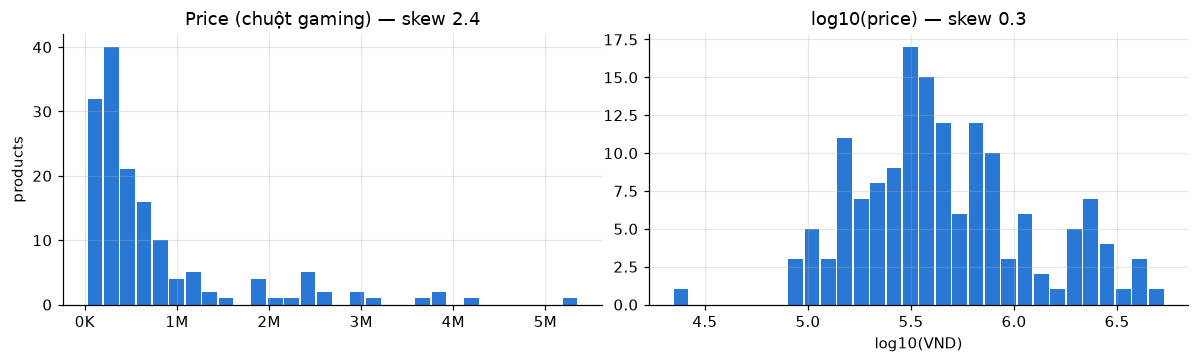

In [7]:
prices = main.loc[main["keyword"] == KEYWORDS[0], "price"]

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.4))
left.hist(prices, bins=30, color=BLUE, rwidth=0.9)
left.set_title(f"Price ({KEYWORDS[0]}) — skew {prices.skew():.1f}")
left.xaxis.set_major_formatter(vnd_short)
left.set_ylabel("products")

right.hist(np.log10(prices), bins=30, color=BLUE, rwidth=0.9)
right.set_title(f"log10(price) — skew {np.log10(prices).skew():.1f}")
right.set_xlabel("log10(VND)")
plt.tight_layout()

Prices are strongly **right-skewed**: most products are cheap, a few are very expensive. On a log scale the shape is close to symmetric, so the IQR rule for unusual prices is applied to `log10(price)` (on raw prices the lower fence would be negative and could never catch a suspiciously cheap listing).

In [8]:
rows = []
for keyword, group in main.groupby("keyword", sort=False):
    low, high = price_fences(group["price"])
    rows.append({"keyword": keyword, "low fence": int(round(low, -3)), "high fence": int(round(high, -3)),
                 "unusual products": int((group["price_flag"] != "normal").sum())})
pd.DataFrame(rows).set_index("keyword")

,low fence,high fence,unusual products
keyword,,,
chuột gaming,40000,4768000,2
tai nghe bluetooth,148000,5492000,4
nồi chiên không dầu,649000,12879000,1


In [9]:
main.loc[main["price_flag"] != "normal", ["keyword", "name", "price", "price_flag"]].sort_values(["keyword", "price"])

,keyword,name,price,price_flag
71,chuột gaming,Chuột Game Chuyên Dụng Đèn Led - Màu ngẫu nhiên,22093,low
120,chuột gaming,Chuột không dây Gaming Logitech Pro X2 Superstrike ...,5359000,high
397,nồi chiên không dầu,"Nồi Chiên Không Dầu 8L , Nướng Gà Cả Con - Bếp Nướ...",599000,low
301,tai nghe bluetooth,Tai nghe Bluetooth True Wireless Xiaomi FlipBuds Pr...,5990000,high
345,tai nghe bluetooth,Tai nghe Bluetooth True Wireless JBL Live Beam 4 - ...,6290000,high
348,tai nghe bluetooth,Tai nghe Bluetooth Apple AirPods Pro 3 - MFHP4ZP/A,6290000,high
367,tai nghe bluetooth,Tai nghe Bluetooth True Wireless Sony WF-1000XM6 - ...,9564000,high


Only **7 of 411** products in the main categories are flagged, and they are of two kinds:

- **too expensive** — flagship products (AirPods Pro 3, Sony WF-1000XM6, Logitech Pro X2) that are real but belong to a different market tier;
- **too cheap** — a 22 000 ₫ "gaming mouse" (almost certainly a different product or a mistake) and a 599 000 ₫ 8-litre air fryer, cheaper than every other air fryer in the results.

A flag is not proof that a listing is fake; it means *check before trusting this price*. Flagged products are excluded from the reference prices below.

**So what?** A shopper who sees a gaming mouse under the low fence (40K) should read the listing carefully before buying. For the analysis, setting these 7 listings aside keeps a 22K or a 9.6M product from moving the reference prices.

## 3. Reference prices

Computed on normal prices only (see `analysis/pricing.py`):

- **floor** — 10th percentile: 90 % of listings cost more. A much cheaper listing deserves a closer look.
- **Q1–Q3** — the common price range (middle 50 % of listings).
- **sales-weighted median** — the median price *of units sold*: line up every unit sold by price and take the middle one.

In [10]:
rows = []
for keyword, group in main.groupby("keyword", sort=False):
    rows.append({"keyword": keyword, **price_band(group)})
bands = pd.DataFrame(rows).set_index("keyword")[["floor", "q1", "median", "q3", "sales_weighted_median"]]
(bands / 1000).astype(int)  # in thousand VND

,floor,q1,median,q3,sales_weighted_median
keyword,,,,,
chuột gaming,150,244,398,793,472
tai nghe bluetooth,355,560,699,1305,525
nồi chiên không dầu,1330,1994,2690,4201,2173


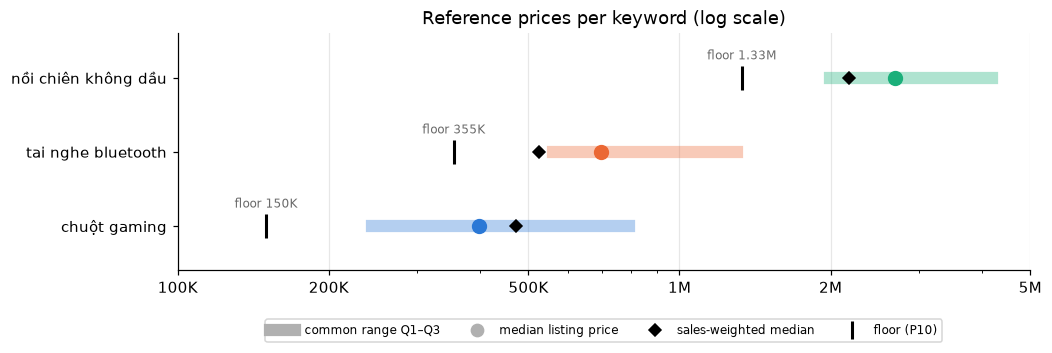

In [11]:
fig, ax = plt.subplots(figsize=(10, 2.8))
for y, (keyword, band) in enumerate(bands.iterrows()):
    color = COLORS[keyword]
    ax.plot([band["q1"], band["q3"]], [y, y], color=color, linewidth=8, alpha=0.35)
    ax.plot(band["floor"], y, "|", color="black", markersize=16, markeredgewidth=2)
    ax.plot(band["median"], y, "o", color=color, markersize=9)
    ax.plot(band["sales_weighted_median"], y, "D", color="black", markersize=6)
    ax.annotate(f"floor {vnd_short(band['floor'])}", (band["floor"], y), xytext=(0, 12),
                textcoords="offset points", ha="center", fontsize=8, color="dimgray")
ax.set_xscale("log")
ax.set_xticks([100_000, 200_000, 500_000, 1_000_000, 2_000_000, 5_000_000])
ax.xaxis.set_major_formatter(vnd_short)
ax.xaxis.set_minor_formatter(FuncFormatter(lambda x, _: ""))  # hide the extra log-scale labels
ax.set_yticks(range(len(bands)), bands.index)
ax.set_ylim(-0.6, len(bands) - 0.4)
ax.grid(axis="y", visible=False)
ax.set_title("Reference prices per keyword (log scale)")
ax.legend(handles=[  # one legend entry per marker, drawn in neutral colours
    plt.Line2D([], [], color=GRAY, linewidth=8, label="common range Q1–Q3"),
    plt.Line2D([], [], marker="o", linestyle="", color=GRAY, markersize=8, label="median listing price"),
    plt.Line2D([], [], marker="D", linestyle="", color="black", markersize=6, label="sales-weighted median"),
    plt.Line2D([], [], marker="|", linestyle="", color="black", markersize=12, markeredgewidth=2, label="floor (P10)"),
], loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4, fontsize=8)
fig.savefig(FIGURES / "reference_prices.png", dpi=150, bbox_inches="tight")

### Is the sales-weighted median a market price, or one product's price?

If one product sold close to half of all units, the middle unit is very likely that product, and the "market" number is really the price of one product. So I look at the three best sellers of each keyword, then recompute the weighted median without the top 1 and the top 3 of them.

Rule of thumb: if the units priced *below* the best seller are less than 50 % of all units, and the units priced *up to and including* it are more than 50 %, the weighted median is exactly the best seller's price.

In [12]:
# The three best sellers of each keyword
rows = []
for keyword, group in normal.groupby("keyword", sort=False):
    total = group["sold"].sum()
    for _, product in group.nlargest(3, "sold").iterrows():
        rows.append({"keyword": keyword, "name": product["name"][:50], "price": product["price"],
                     "% of units": round(100 * product["sold"] / total, 1)})
pd.DataFrame(rows)

,keyword,name,price,% of units
0,chuột gaming,Chuột Gaming Logitech G102 Gen 2 Lightsync - Hàng,471900,37.3
1,chuột gaming,Chuột game không dây Lightspeed Logitech G304 - Cả,805000,28.6
2,chuột gaming,Chuột game hiệu suất cao Logitech G502 Hero RGB Li,1091920,8.3
3,tai nghe bluetooth,Tai Nghe Bluetooth Cao Cấp EQ2 5.3 Pin 7h Âm Thanh,359000,44.5
4,tai nghe bluetooth,Tai nghe Bluetooth Apple AirPods 4,3090000,33.8
5,tai nghe bluetooth,Tai Nghe Bluetooth FIRO Fi5 Pro2 - Tai Nghe Không,739000,5.3
6,nồi chiên không dầu,Nồi Chiên Không Dầu Điện Tử Lock&Lock EJF296BLK (7,2172938,87.4
7,nồi chiên không dầu,Nồi Chiên Không Dầu Locknlock Visible Air Fryer CU,2390040,5.2
8,nồi chiên không dầu,Nồi chiên không dầu điện tử Philips HD9252/90 (4.1,2495000,2.2


In [13]:
def weighted_median_without_top(group, top):
    """Sales-weighted median after removing the `top` best-selling products."""
    rest = group.sort_values("sold", ascending=False).iloc[top:]
    return weighted_median(rest["price"], rest["sold"])


rows = []
for keyword, group in normal.groupby("keyword", sort=False):
    total = group["sold"].sum()
    best = group.loc[group["sold"].idxmax()]
    sales_weighted = weighted_median(group["price"], group["sold"])
    rows.append({
        "keyword": keyword,
        "top 3: % of units": round(100 * group["sold"].nlargest(3).sum() / total, 1),
        "units below best seller's price %": round(100 * group.loc[group["price"] < best["price"], "sold"].sum() / total, 1),
        "units up to its price %": round(100 * group.loc[group["price"] <= best["price"], "sold"].sum() / total, 1),
        "sales-weighted median": int(sales_weighted),
        "without top 1": int(weighted_median_without_top(group, 1)),
        "without top 3": int(weighted_median_without_top(group, 3)),
        "median listing": int(group["price"].median()),
        "gap to median listing %": round(100 * (sales_weighted / group["price"].median() - 1), 1),
    })
pd.DataFrame(rows).set_index("keyword").T

keyword,chuột gaming,tai nghe bluetooth,nồi chiên không dầu
top 3: % of units,74.1,83.5,94.8
units below best seller's price %,16.1,4.1,3.3
units up to its price %,53.4,48.6,90.7
sales-weighted median,471900.0,525000.0,2172938.0
without top 1,805000.0,3090000.0,2390040.0
without top 3,355000.0,689000.0,1350000.0
median listing,398000.0,699000.0,2690000.0
gap to median listing %,18.6,-24.9,-19.2


| | floor (P10) | common range (Q1–Q3) | median listing | sales-weighted median | best seller's share of units | weighted median without the best seller |
|---|---|---|---|---|---|---|
| chuột gaming | 150K | 244K – 793K | 398K | 472K | 37 % | 805K |
| tai nghe bluetooth (true wireless) | 355K | 560K – 1.3M | 699K | 525K | 45 % | 3.09M |
| nồi chiên không dầu | 1.33M | 1.99M – 4.2M | 2.69M | 2.17M | 87 % | 2.39M |

**The sales-weighted median is the price of one or two products, not of the market.**

- **Gaming mice:** 472K is exactly the price of the Logitech G102, which alone sold 37 % of all units. Without it, the number jumps to 805K, the price of the next best seller (Logitech G304, 29 % of units).
- **Air fryers:** 2.17M is the price of the Lock&Lock EJF296BLK, 87 % of all units. Without it: 2.39M, again the price of the next best seller.
- **Earbuds:** the 359K best seller (45 % of units) brings the running total to 48.6 %, so the middle unit falls on a small 525K product just past the 50 % line. A few more sales of the best seller would move the number to 359K; without the best seller it jumps to 3.09M (AirPods 4, 34 % of units).

Even without the top 3 the number keeps moving (355K, 689K, 1.35M), because the top 3 products take 74–95 % of all units and few units are left. So the gap between the median listing and the sales-weighted median (+19 % for mice, −25 % and −19 % for the others) does **not** mean that buyers in general pay more or less than listing prices. It shows how **concentrated** these markets are (next section).

**So what?** A seller should not read the sales-weighted median as "the price buyers accept": here it is the price of the current best seller. The useful benchmarks are the best sellers themselves (their price and their share of units) and the common listing range Q1–Q3 for everyone else.

## 4. Which price segment sells — and how concentrated are sales?

Segments are cut at Q1 and Q3: **budget** (cheapest 25 %), **mid** (middle 50 %), **premium** (most expensive 25 %). If buyers did not care about price, each segment's share of units sold would equal its share of listings.

In [14]:
def segment_shares(group):
    band = price_band(group)
    segment = pd.cut(group["price"], [0, band["q1"], band["q3"], np.inf], labels=["budget", "mid", "premium"])
    table = group.groupby(segment, observed=False).agg(listings=("price", "size"), sold=("sold", "sum"))
    return (100 * table / table.sum()).rename(columns={"listings": "% of listings", "sold": "% of units sold"})

tables = {}
for keyword, group in normal.groupby("keyword", sort=False):
    tables[keyword] = segment_shares(group)
segments = pd.concat(tables)  # one table, with the keyword as the first index level
segments.round(1)

% of listings  % of units sold
                    price                                  
chuột gaming        budget            25.3              4.3
                    mid               49.3             57.4
                    premium           25.3             38.3
tai nghe bluetooth  budget            26.9             51.0
                    mid               47.8             13.3
                    premium           25.4             35.7
nồi chiên không dầu budget            25.1              3.2
                    mid               49.7             96.4
                    premium           25.1              0.4

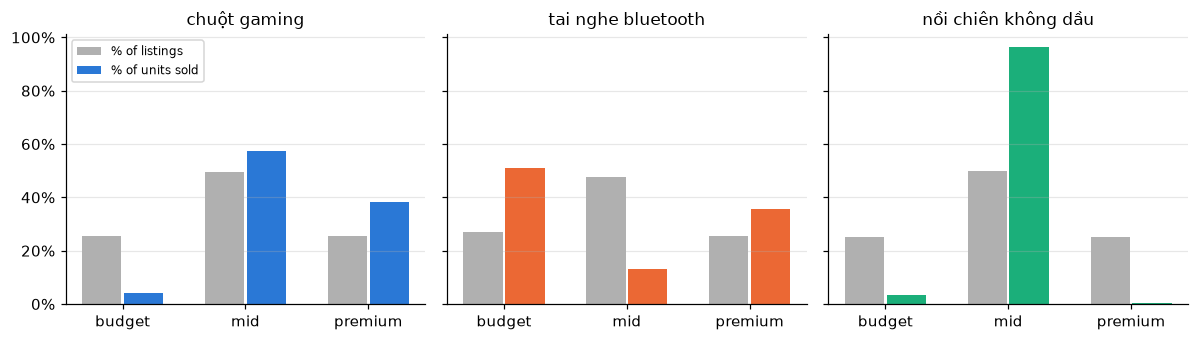

In [15]:
fig, axes = plt.subplots(1, len(KEYWORDS), figsize=(11, 3.2), sharey=True)
x = np.arange(3)
for ax, keyword in zip(axes, KEYWORDS):
    table = segments.loc[keyword]
    ax.bar(x - 0.17, table["% of listings"], width=0.32, color=GRAY, label="% of listings")
    ax.bar(x + 0.17, table["% of units sold"], width=0.32, color=COLORS[keyword], label="% of units sold")
    ax.set_xticks(x, table.index)
    ax.set_title(keyword, fontsize=11)
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.grid(axis="x", visible=False)
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
fig.savefig(FIGURES / "segments.png", dpi=150, bbox_inches="tight")

If price did not matter, the coloured bars would match the gray ones. They do not:

- **Gaming mice:** the cheapest quarter of listings gets only **4 %** of units sold — the budget segment is crowded but does not sell.
- **Wireless earbuds:** the opposite — the budget segment (≤ 560K) takes **51 %** of units sold.
- **Air fryers:** **96 %** of units sold are in the mid range (2.0M – 4.2M).

Caution: in every category one or two best sellers weigh heavily (next table), so these shares describe a few products rather than whole segments. For earbuds, most of the budget segment's 51 % is the single 359K best seller (45 % of all units).

**So what?** For gaming mice and air fryers, a seller does not win volume by being the cheapest: units go to the mid range (and, for mice, the premium range), where the best sellers are. For earbuds a cheap product can sell, but here it is one product, not the whole budget segment.

In [16]:
rows = []
for keyword, group in normal.groupby("keyword", sort=False):
    sold = group["sold"].sort_values(ascending=False)
    top10 = sold.head(max(1, round(len(sold) * 0.10)))  # the best-selling 10 % of listings
    rows.append({"keyword": keyword,
                 "top 10% of listings: % of units sold": round(100 * top10.sum() / sold.sum(), 1),
                 "listings with 0 sold %": round(100 * (sold == 0).mean(), 1),
                 "best seller: % of units sold": round(100 * sold.iloc[0] / sold.sum(), 1)})
pd.DataFrame(rows).set_index("keyword")

,top 10% of listings: % of units sold,listings with 0 sold %,best seller: % of units sold
keyword,,,
chuột gaming,95.6,39.3,37.3
tai nghe bluetooth,90.9,37.3,44.5
nồi chiên không dầu,99.1,68.4,87.4


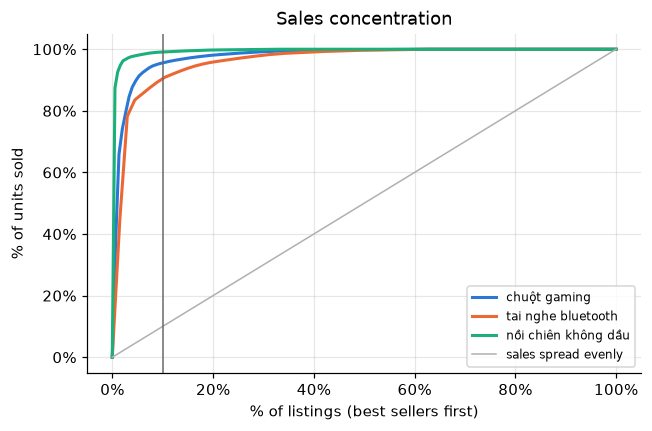

In [17]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for keyword, group in normal.groupby("keyword", sort=False):
    sold = group["sold"].sort_values(ascending=False).to_numpy()
    listing_share = np.arange(len(sold) + 1) / len(sold) * 100           # starts at (0 %, 0 %)
    sold_share = np.concatenate([[0], sold.cumsum()]) / sold.sum() * 100
    ax.plot(listing_share, sold_share, color=COLORS[keyword], linewidth=2, label=keyword)
ax.plot([0, 100], [0, 100], color=GRAY, linewidth=1, label="sales spread evenly")
ax.axvline(10, color="dimgray", linewidth=1)
ax.set_xlabel("% of listings (best sellers first)")
ax.set_ylabel("% of units sold")
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set_title("Sales concentration")
ax.legend(fontsize=8, loc="lower right")
fig.savefig(FIGURES / "concentration.png", dpi=150, bbox_inches="tight")

Sales are **extremely concentrated**: the top 10 % of listings take **91–99 %** of all units sold, and **37–68 %** of listings have never sold a single unit. In air fryers one product (Lock&Lock EJF296BLK, 2.17M) accounts for 87 % of the units sold.

**So what?** For a new seller, the number of listings overstates the competition: each market is decided by a handful of products, and most listings never sell. It also means that any number weighted by sales, like the sales-weighted median in section 3, describes those few products, not the market.

## 5. What is related to sales?

Spearman correlation (rank-based) is used because sales and prices are heavily skewed and the relationships do not need to be linear.

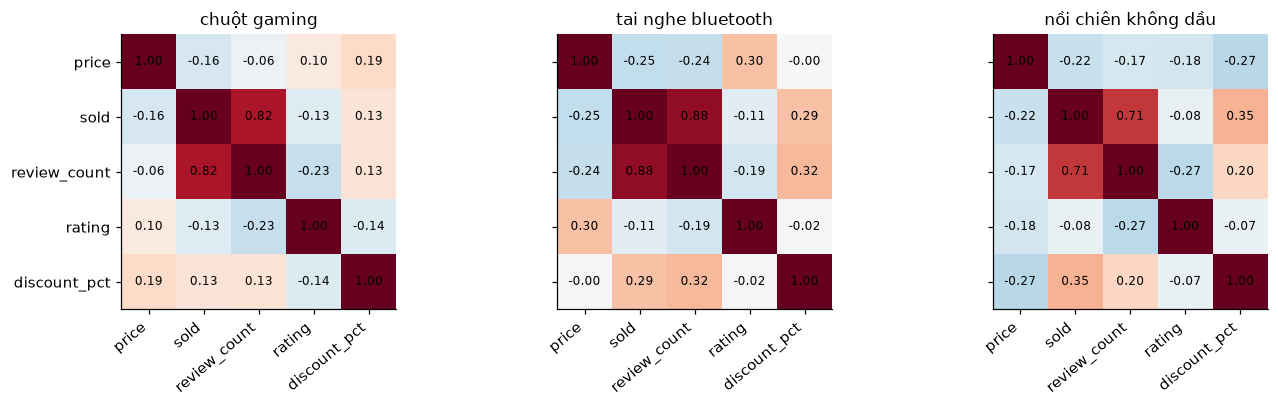

In [18]:
columns = ["price", "sold", "review_count", "rating", "discount_pct"]
corr = {keyword: group[columns].corr(method="spearman") for keyword, group in normal.groupby("keyword", sort=False)}

fig, axes = plt.subplots(1, len(KEYWORDS), figsize=(13, 3.8))
for ax, keyword in zip(axes, KEYWORDS):
    matrix = corr[keyword]
    ax.imshow(matrix, cmap="RdBu_r", vmin=-1, vmax=1)  # blue = negative, red = positive
    ax.set_xticks(range(len(columns)), columns, rotation=40, ha="right")
    ax.set_yticks(range(len(columns)), columns if ax is axes[0] else [])
    ax.grid(False)
    ax.set_title(keyword, fontsize=11)
    for i in range(len(columns)):
        for j in range(len(columns)):
            ax.text(j, i, f"{matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.tight_layout()

In [19]:
# Correlation with units sold, on all products and only on products that sold at least once:
# many products have 0 sold and 0 reviews, and such a block of ties can inflate a rank correlation.
def correlation_with_sold(data):
    """Spearman rho between units sold and each other column."""
    return data[columns].corr(method="spearman")["sold"].drop("sold")


results = {}
for keyword, group in normal.groupby("keyword", sort=False):
    results[(keyword, "all")] = correlation_with_sold(group)
    results[(keyword, "sold > 0")] = correlation_with_sold(group[group["sold"] > 0])

print("products:              ", normal.groupby("keyword", sort=False).size().to_dict())
print("products with sold > 0:", normal[normal["sold"] > 0].groupby("keyword", sort=False).size().to_dict())
print("products with sold = 0:", int((normal["sold"] == 0).sum()),
      "- of which also 0 reviews:", int(((normal["sold"] == 0) & (normal["review_count"] == 0)).sum()))
print("rated products with sold = 0:", int((normal["rating"].notna() & (normal["sold"] == 0)).sum()))
pd.DataFrame(results).round(2)

products:               {'chuột gaming': 150, 'tai nghe bluetooth': 67, 'nồi chiên không dầu': 187}
products with sold > 0: {'chuột gaming': 91, 'tai nghe bluetooth': 42, 'nồi chiên không dầu': 59}
products with sold = 0: 212 - of which also 0 reviews: 212
rated products with sold = 0: 0


chuột gaming          tai nghe bluetooth           \
                      all sold > 0                all sold > 0   
price               -0.16    -0.19              -0.25    -0.16   
review_count         0.82     0.79               0.88     0.83   
rating              -0.13    -0.13              -0.11    -0.11   
discount_pct         0.13     0.16               0.29     0.43   

             nồi chiên không dầu           
                             all sold > 0  
price                      -0.22    -0.31  
review_count                0.71     0.72  
rating                     -0.08    -0.08  
discount_pct                0.35     0.35

- **Reviews ↔ sold: ρ = 0.71 to 0.88** on all products, **0.72 to 0.83** on products that sold at least once. 37–68 % of products have never sold, all of them with 0 reviews too, and such a big block of ties at (0, 0) can inflate a rank correlation. Here removing it changes ρ by at most 0.05, so the relationship is not just the zeros. It is still not two independent measurements: a review needs a purchase, and both numbers grow with the time a product has been on sale. So this mainly shows that the "sold" counts are consistent with the reviews (a data check), not that reviews drive sales.
- **Price ↔ sold: ρ = −0.16 to −0.25** (−0.16 to −0.31 without the zeros). Cheaper products sell slightly more, but price explains little on its own.
- **Rating ↔ sold: ρ ≈ −0.1, no relationship**, and the same in both columns: pandas only uses rows where both values exist, and every rated product has sold at least once. Ratings are compressed: the median rated product has 5.0★ and 69 % of all products have no rating at all, so stars barely separate products. This is why the deal score ranks a Bayesian-adjusted rating instead of raw stars.
- **Discount ↔ sold: ρ = 0.13 to 0.35** (0.16 to 0.43 without the zeros).

**So what?** The number of reviews is a usable stand-in for popularity when sales are not shown, but the star rating is not: a shopper learns more from *how many* people reviewed a product than from its stars.

In [20]:
# Rating distribution of rated products: how much room is there to tell products apart?
normal.groupby("keyword", sort=False)["rating"].describe()[["count", "mean", "25%", "50%", "75%"]].round(2)

,count,mean,25%,50%,75%
keyword,,,,,
chuột gaming,58.0,4.56,4.50,5.0,5.0
tai nghe bluetooth,32.0,4.68,4.65,5.0,5.0
nồi chiên không dầu,28.0,4.74,4.78,5.0,5.0


In [21]:
# Discounted vs not discounted
data = normal.assign(discounted=normal["discount_pct"] > 0)
table = data.groupby(["keyword", "discounted"]).agg(
    products=("price", "size"), median_price=("price", "median"), median_sold=("sold", "median"))
table.round(1)

products  median_price  median_sold
keyword             discounted                                     
chuột gaming        False            136      382000.0          1.0
                    True              14      799500.0          2.0
nồi chiên không dầu False            144     2942900.0          0.0
                    True              43     2190000.0          1.0
tai nghe bluetooth  False             55      699000.0          1.0
                    True              12      744000.0         12.5

Discounted products have higher median sales (earbuds: 12.5 vs 1 unit). This is a **correlation, not proof that discounts cause sales**: sellers may promote products that already sell, and only today's discount is visible — there is no price history to check whether the "original price" was ever charged.

**So what?** Discounts are worth testing, but this snapshot cannot say they cause sales. With daily snapshots, the same product could be compared before and after a price cut.

## 6. What does the deal score pick, and is it validated?

`deal_score = 100 × (0.3 × cheap rank + 0.4 × sold rank + 0.3 × adjusted-rating rank)`, computed inside each category; the rating is adjusted with a Bayesian average so that 5★ from one review does not beat 4.8★ from a thousand.

In [22]:
# The 3 highest scores of each keyword
top_deals = normal.sort_values(["keyword", "deal_score"], ascending=[True, False])
top_deals = top_deals.groupby("keyword").head(3)
top_deals[["keyword", "name", "price", "sold", "rating", "review_count", "deal_score"]]

,keyword,name,price,sold,rating,review_count,deal_score
128,chuột gaming,Chuột Dareu LM103- Màu đen - Hàng Chính hãng,80000,100,5.0,7,96.1
10,chuột gaming,Chuột LED RGB 3200 DPI Gaming Mouse A868 chống mỏi ...,185000,106,4.8,13,90.8
106,chuột gaming,Chuột máy tính chuyên phòng Game Newmen G7Plus_Hàng...,250000,204,4.8,37,89.2
379,nồi chiên không dầu,"Nồi chiên không dầu thế hệ mới dung tích lớn, công ...",650000,14,5.0,1,95.2
450,nồi chiên không dầu,Nồi chiên không dầu Philips 6.2 lít NA130/00 - Hàn...,1350000,126,4.8,27,94.9
421,nồi chiên không dầu,Nồi chiên không dầu thủy tinh Mishio MK373 - Dung t...,999000,16,5.0,1,94.7
216,tai nghe bluetooth,Tai nghe bluetooth nhét tai TWS ROCK EB710 - Hàng c...,325000,47,5.0,10,94.8
332,tai nghe bluetooth,Tai nghe Bluetooth True Wireless Redmi Buds 6 Play ...,328000,26,4.8,5,88.2
174,tai nghe bluetooth,Tai Nghe Bluetooth Cao Cấp EQ2 5.3 Pin 7h Âm Thanh ...,359000,1143,4.7,190,86.1


In [23]:
# Are the top deals cheaper than the median, and do they sell?
summary = []
for keyword, group in normal.groupby("keyword", sort=False):
    best = group.nlargest(10, "deal_score")
    summary.append({"keyword": keyword,
                     "median price, top 10 deals": best["price"].median(),
                     "median price, all": group["price"].median(),
                     "median sold, top 10 deals": best["sold"].median(),
                     "median sold, all": group["sold"].median()})
pd.DataFrame(summary).set_index("keyword").round(0).astype(int)

,"median price, top 10 deals","median price, all","median sold, top 10 deals","median sold, all"
keyword,,,,
chuột gaming,194500,398000,54,1
tai nghe bluetooth,542500,699000,26,1
nồi chiên không dầu,1324500,2690000,9,0


The top-10 deals are **cheaper than the median listing** (195K vs 398K for mice, 543K vs 699K for earbuds, 1.32M vs 2.69M for air fryers) and have **sold more** (median 9–54 units, against 0–1 for all products).

**The score behaves as designed, but this is not a validation.** Units sold make up 40 % of the score and a low price another 30 %, so the top-scored products are cheaper and sell more *by construction*. The table above only confirms that the formula works the way I wrote it; it cannot show that a high score predicts a good purchase. The weights 0.3 / 0.4 / 0.3 are my choice, not learned from data.

**So what?** The score is useful as a sorted shortlist ("cheaper than most, already bought by others, well reviewed"), not as a proven recommendation.

### How I would validate it

A fair test has to use information the score has not seen: sales that happen **after** the score is computed (an out-of-time check).

1. Compute the deal score from the snapshot of day *t* (`collect.py` saves one snapshot per keyword every day).
2. Take the snapshot of day *t + 7* and, for the same products, compute `sold_between = sold(t+7) − sold(t)`. `analysis/history.py` already does this, because `sold` is cumulative.
3. Check whether the score ranks next week's sales: Spearman ρ between the score and `sold_between`, and the median `sold_between` of the top 10 against the rest.
4. Compare with a simple baseline that only sorts by `sold` on day *t*. If the score does no better, its price and rating parts add nothing for predicting sales.

This needs two snapshots one week apart, so it is not run here: the sample is a single snapshot. Even then, next week's sales measure popularity, not whether buyers were happy; later reviews or return rates would be better targets, but the public search results do not show them.

## Conclusions

1. **A floor price can be estimated from listings alone:** gaming mouse ≈ 150K, true-wireless earbuds ≈ 355K, air fryer ≈ 1.33M (10th percentile of normal prices). A listing below that deserves a closer look.
2. **"What buyers pay" is the price of the best seller.** The sales-weighted median equals, or sits right next to, the price of the top product (37–87 % of units) and changes completely when that one product is removed. It measures concentration, not a market-wide paid price.
3. **These markets are winner-take-most:** the top 10 % of listings take 91–99 % of the units sold, and 37–68 % of listings have never sold.
4. **Star ratings are a weak signal** (mostly 5★ or missing). The number of reviews follows sales much more closely (Spearman ρ 0.71–0.88, still 0.72–0.83 without unsold products), partly because a review needs a purchase.
5. **The deal score behaves as designed, but it is not validated:** its top products are cheaper and sell more partly by construction. A fair test needs snapshots one week apart (section 6).
6. **Data-quality decisions mattered more than formulas:** analysing one category at a time, treating 0★ as missing and working on log prices changed the results more than any weight in the deal score.

**Limitations:** one snapshot, Tiki only, the first 200 results of each search, cumulative sold counts, and 3 products per keyword deciding most sales-weighted numbers.

**Next step:** collect the same keywords every day, then run the out-of-time check of the deal score and see whether advertised discounts are real.